# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/suyashverma0/flyrank-ml-workspace2/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

In [12]:

import os
import subprocess
from pathlib import Path

repo_path = Path("/content/flyrank-ml-workspace2")

# Clone repository if missing
if not repo_path.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/suyashverma0/flyrank-ml-workspace2.git",
            str(repo_path)
        ],
        check=True
    )

os.chdir(repo_path)

print("Current directory:", os.getcwd())

# Search for the starter CSV
matches = list(repo_path.rglob("content_refresh_anonymized.csv"))

if matches:
    data_path = matches[0]
    print("\nDataset found:", data_path)

    import pandas as pd
    df = pd.read_csv(data_path)

    print("Dataset shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

else:
    print("\nDataset CSV not found in repository.")
    print("Repository folders:")
    print([p.name for p in repo_path.iterdir()])


Dataset shape: (30000, 44)

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
search_volume,27532.0,158.882391,1518.270825,0.0,0.0,10.00,20.00,74000.0
impressions_90d,30000.0,5200.366300,16838.019547,1.0,81.0,731.00,3615.25,517715.0
sessions_90d,30000.0,37.066633,107.069131,1.0,2.0,7.00,27.00,4345.0
word_count,22301.0,3107.760325,1452.382598,8.0,2413.0,2877.00,3666.00,9546.0
days_since_last_update,30000.0,46.098300,42.078709,1.0,20.0,20.00,104.00,373.0
ctr,30000.0,0.510733,3.279162,0.0,0.0,0.07,0.29,100.0
engagement_rate,30000.0,2.534520,8.310096,0.0,0.0,0.00,1.35,100.0
avg_position,30000.0,16.342380,15.216790,0.0,6.2,10.80,22.30,245.0


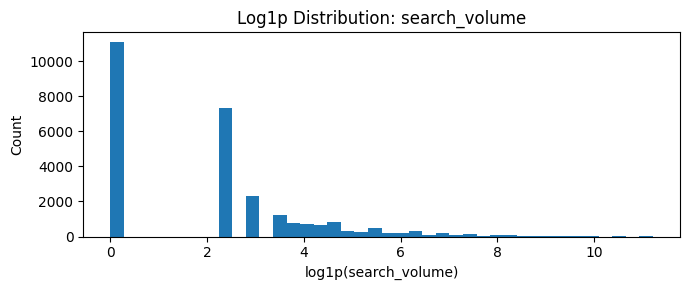

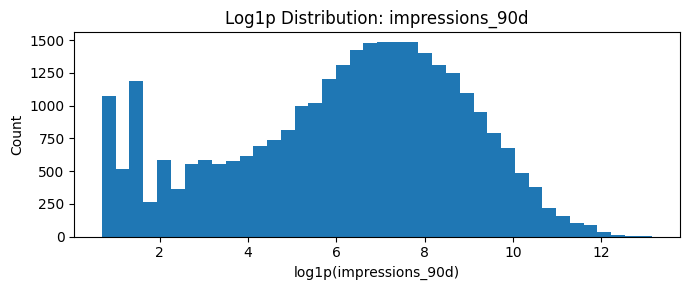

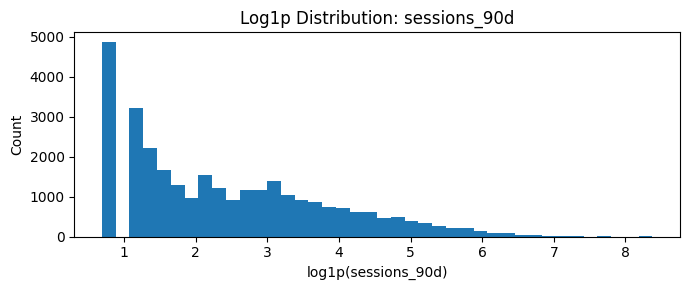

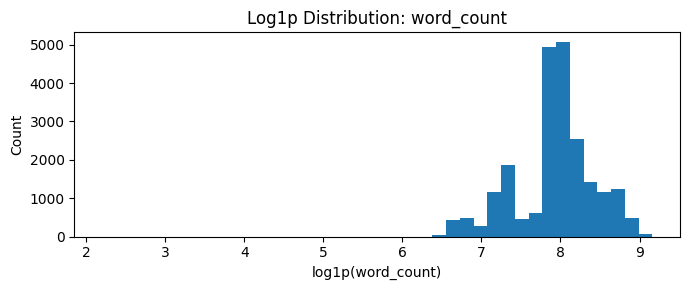

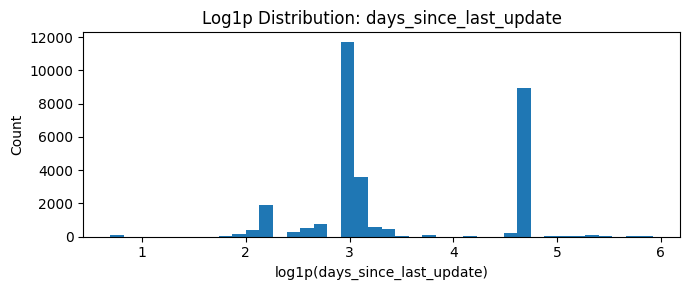

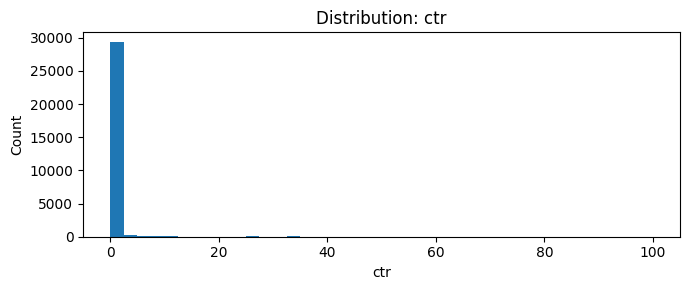

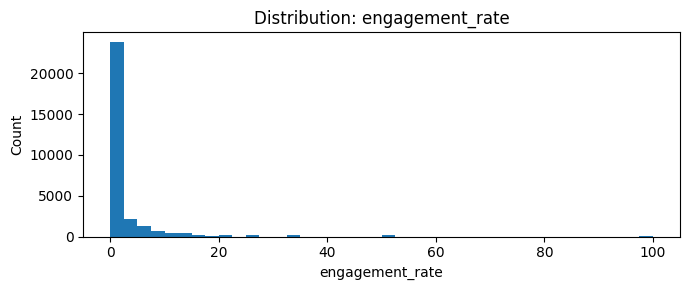

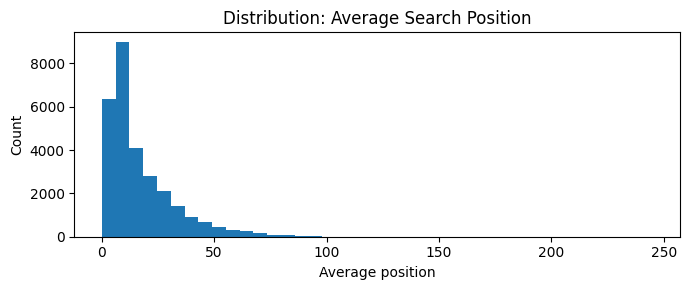

,total_rows,missing_word_count,missing_search_volume
content_type,,,
comparison article,697,0,0
feedly article,2096,0,2096
keyword article,27207,7699,372


In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load dataset
data_path = Path("data/raw/content_refresh_anonymized.csv")
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

# Key fields
fields = [
    "search_volume",
    "impressions_90d",
    "sessions_90d",
    "word_count",
    "days_since_last_update",
    "ctr",
    "engagement_rate",
    "avg_position"
]

print("\nSummary statistics:")
display(df[fields].describe().T)

# Distribution plots
traffic_fields = [
    "search_volume",
    "impressions_90d",
    "sessions_90d",
    "word_count",
    "days_since_last_update"
]

for col in traffic_fields:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    plt.figure(figsize=(7, 3))
    plt.hist(np.log1p(values), bins=40)
    plt.title(f"Log1p Distribution: {col}")
    plt.xlabel(f"log1p({col})")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# Rate distributions
for col in ["ctr", "engagement_rate"]:
    values = df[col].dropna()

    plt.figure(figsize=(7, 3))
    plt.hist(values, bins=40)
    plt.title(f"Distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# Position distribution: exclude zero = unavailable
valid_positions = df.loc[df["avg_position"] > 0, "avg_position"]

plt.figure(figsize=(7, 3))
plt.hist(valid_positions, bins=40)
plt.title("Distribution: Average Search Position")
plt.xlabel("Average position")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Missingness by content type
missingness = (
    df.groupby("content_type")
    .agg(
        total_rows=("content_type", "size"),
        missing_word_count=("word_count", lambda x: x.isna().sum()),
        missing_search_volume=("search_volume", lambda x: x.isna().sum())
    )
)

display(missingness)

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [14]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def run_signal_test(data, x_col, y_col, title, min_rows=50):

    temp = data[[x_col, y_col]].copy()

    temp[x_col] = pd.to_numeric(temp[x_col], errors="coerce")
    temp[y_col] = pd.to_numeric(temp[y_col], errors="coerce")

    temp = temp.dropna()

    # Exclude invalid negative values
    temp = temp[
        (temp[x_col] >= 0) &
        (temp[y_col] >= 0)
    ].copy()

    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    print("Total rows:", len(temp))

    if len(temp) < min_rows:
        print("Insufficient data for a reliable test.")
        return None

    # Spearman correlation handles heavy tails better than Pearson
    correlation = temp[x_col].corr(
        temp[y_col],
        method="spearman"
    )

    print("Spearman correlation:", round(correlation, 4))

    # Create quantile groups
    temp["group"] = pd.qcut(
        temp[x_col],
        q=4,
        duplicates="drop"
    )

    summary = (
        temp.groupby("group", observed=False)
        .agg(
            sample_size=(y_col, "size"),
            median_x=(x_col, "median"),
            median_y=(y_col, "median")
        )
        .reset_index()
    )

    display(summary)

    if (summary["sample_size"] < min_rows).any():
        print("WARNING: At least one group has fewer than 50 rows.")
        print("Do not make a strong verdict from this test.")

    return {
        "correlation": correlation,
        "summary": summary,
        "rows": len(temp)
    }


# TEST 1: Search volume vs impressions
test1_data = df[
    df["search_volume"].notna() &
    (df["search_volume"] > 0)
]

test1 = run_signal_test(
    test1_data,
    "search_volume",
    "impressions_90d",
    "TEST 1: Search Volume vs Impressions"
)


# TEST 1 robustness check: keyword articles only
keyword_data = test1_data[
    test1_data["content_type"] == "keyword article"
]

test1_robustness = run_signal_test(
    keyword_data,
    "search_volume",
    "impressions_90d",
    "TEST 1 ROBUSTNESS: Keyword Articles Only"
)


# TEST 2: Word count vs impressions
test2_data = df[
    df["word_count"].notna() &
    (df["word_count"] > 0)
]

test2 = run_signal_test(
    test2_data,
    "word_count",
    "impressions_90d",
    "TEST 2: Word Count vs Impressions"
)


# TEST 3: Content freshness vs impressions
test3_data = df[
    df["days_since_last_update"].notna()
]

test3 = run_signal_test(
    test3_data,
    "days_since_last_update",
    "impressions_90d",
    "TEST 3: Days Since Last Update vs Impressions"
)


TEST 1: Search Volume vs Impressions
Total rows: 16451
Spearman correlation: 0.0012


,group,sample_size,median_x,median_y
0,"(9.999, 20.0]",9601,10.0,874.0
1,"(20.0, 70.0]",3339,40.0,870.0
2,"(70.0, 74000.0]",3511,260.0,826.0



TEST 1 ROBUSTNESS: Keyword Articles Only
Total rows: 16451
Spearman correlation: 0.0012


,group,sample_size,median_x,median_y
0,"(9.999, 20.0]",9601,10.0,874.0
1,"(20.0, 70.0]",3339,40.0,870.0
2,"(70.0, 74000.0]",3511,260.0,826.0



TEST 2: Word Count vs Impressions
Total rows: 22301
Spearman correlation: 0.2986


,group,sample_size,median_x,median_y
0,"(7.999, 2413.0]",5576,1450.0,91.0
1,"(2413.0, 2877.0]",5586,2688.0,1096.5
2,"(2877.0, 3666.0]",5566,3121.0,889.0
3,"(3666.0, 9546.0]",5573,4896.0,1495.0



TEST 3: Days Since Last Update vs Impressions
Total rows: 30000
Spearman correlation: 0.2542


,group,sample_size,median_x,median_y
0,"(0.999, 20.0]",15866,20.0,363.0
1,"(20.0, 104.0]",13816,104.0,1262.0
2,"(104.0, 373.0]",318,183.0,30.0


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [15]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
flag_data = df[
    (df["impressions_90d"] >= 300) &
    (df["avg_position"] > 0)
].copy()

flag_data["position_flag"] = np.where(
    flag_data["avg_position"] > 20,
    "weak_search_position",
    "position_20_or_better"
)

flag_summary = (
    flag_data.groupby("position_flag")
    .agg(
        sample_size=("content_id", "count"),
        total_impressions=("impressions_90d", "sum"),
        total_clicks=("clicks_90d", "sum"),
        median_position=("avg_position", "median")
    )
    .reset_index()
)

# Weighted CTR = total clicks / total impressions * 100
flag_summary["weighted_ctr"] = (
    flag_summary["total_clicks"] /
    flag_summary["total_impressions"] * 100
)

display(flag_summary)

print("\nSample size check:")
display(
    flag_summary[["position_flag", "sample_size"]]
)

if len(flag_summary) == 2 and (flag_summary["sample_size"] >= 50).all():

    weak_ctr = flag_summary.loc[
        flag_summary["position_flag"] == "weak_search_position",
        "weighted_ctr"
    ].iloc[0]

    better_ctr = flag_summary.loc[
        flag_summary["position_flag"] == "position_20_or_better",
        "weighted_ctr"
    ].iloc[0]

    print("\nWeak-position weighted CTR:", round(weak_ctr, 4))
    print("Position 20 or better weighted CTR:", round(better_ctr, 4))

    if weak_ctr < better_ctr:
        print("Observed direction: SUPPORTS the flag assumption")
    elif weak_ctr > better_ctr:
        print("Observed direction: OPPOSES the flag assumption")
    else:
        print("Observed direction: NO DIFFERENCE")

else:
    print("Insufficient sample size for a firm flag verdict.")

,position_flag,sample_size,total_impressions,total_clicks,median_position,weighted_ctr
0,position_20_or_better,13205,119256345,426306,8.4,0.357470
1,weak_search_position,5547,35949286,53883,29.9,0.149886



Sample size check:


,position_flag,sample_size
0,position_20_or_better,13205
1,weak_search_position,5547



Weak-position weighted CTR: 0.1499
Position 20 or better weighted CTR: 0.3575
Observed direction: SUPPORTS the flag assumption


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

In [16]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("ML-06 Signal Audit completed.")

print("\nSignal 1 available:", test1 is not None)
print("Signal 2 available:", test2 is not None)
print("Signal 3 available:", test3 is not None)

print("\nFlag-linked test rows:", len(flag_data))
print("Flag-linked groups:", len(flag_summary))

print("\nRemember:")
print("- Use observed results for final verdicts.")
print("- Do not make causal claims.")
print("- Do not use trend_direction or trend_pct.")
print("- Do not make firm claims from groups below 50 rows.")

ML-06 Signal Audit completed.

Signal 1 available: True
Signal 2 available: True
Signal 3 available: True

Flag-linked test rows: 18752
Flag-linked groups: 2

Remember:
- Use observed results for final verdicts.
- Do not make causal claims.
- Do not use trend_direction or trend_pct.
- Do not make firm claims from groups below 50 rows.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.